In [20]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory


import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [21]:
!pip install hazm

In [38]:
import pandas as pd
import numpy as np 
import pandas as pd 
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from collections import Counter
import torch
from torch.utils.data import TensorDataset,DataLoader
import torch.nn as nn
import sys
from pathlib import Path
import re
from hazm import Normalizer
import torch.nn.utils.rnn as rnn_utils
import matplotlib.pyplot as plt

**installing hazm**

In [23]:



# sys.path.insert(0, "/kaggle/working/pkgs")

# for k in list(sys.modules.keys()):
#     if k == "hazm" or k.startswith("hazm."):
#         del sys.modules[k]

# init_path = Path("/kaggle/working/pkgs/hazm/__init__.py")

# minimal_init = """\
# # Minimal hazm init for Kaggle (avoid embedding/dependency imports)
# from .normalizer import Normalizer
# __all__ = ["Normalizer"]
# """

# init_path.write_text(minimal_init, encoding="utf-8")
# print("Patched:", init_path)


In [24]:

sys.path.insert(0, "/kaggle/working/pkgs")


normalizer = Normalizer(
    correct_spacing=True,
    remove_diacritics=True,
    remove_specials_chars=False,
    decrease_repeated_chars=False
)

print(normalizer.normalize("سلاممممم!!!  كیفیتش عاليه"))


سلاممممم!!! کیفیتش عالیه


### 📝 Text Normalization: Reducing Character & Punctuation Repetitions

In user-generated content, especially on platforms like **Digikala**, users often use "elongated words" or "excessive punctuation" to emphasize their emotions (e.g., "عالییییی" for "Excellent" or "خوبه!!!!" for "It's good!!!!"). 

To ensure our Sentiment Analysis model treats these variations consistently, we implement the following:

1. **`reduce_char_repetition`**: Uses Regular Expressions (Regex) to detect consecutive identical characters and reduces them to a maximum of 2 repetitions (e.g., "عالییییی" $\rightarrow$ "عالیی").
2. **`reduce_punct_repetition`**: Specifically targets Persian and English punctuation (dots, exclamation marks, etc.) to prevent noise in the data.
3. **`remove_exaggeration`**: A wrapper function that cleans the text from both types of exaggerations.

**Why this matters:** This process significantly reduces the vocabulary size (dimensionality) and helps the model understand that "Bad" and "Baaaaad" carry the same semantic meaning, leading to better classification accuracy.

In [25]:
def reduce_char_repetition(text: str, max_rep: int = 2) -> str:
    pattern = re.compile(rf"(.)\1{{{max_rep},}}")
    return pattern.sub(lambda m: m.group(1) * max_rep, text)
def reduce_punct_repetition(text: str, max_rep: int = 2) -> str:
    punct = r"[!！?？\.…،,؛;:]"
    pattern = re.compile(rf"({punct})\1{{{max_rep},}}")
    return pattern.sub(lambda m: m.group(1) * max_rep, text)
def remove_exaggeration(text: str, max_rep: int = 2) -> str:
    text = str(text)
    text = reduce_char_repetition(text, max_rep=max_rep)
    text = reduce_punct_repetition(text, max_rep=max_rep)
    return text
    

## Split dataset and preprocess

In [26]:


splits = {'train': 'train.csv', 'validation': 'validation.csv', 'test': 'test.csv'}
df = pd.read_csv("hf://datasets/ParsiAI/snappfood-sentiment-analysis/" + splits["train"])

df = df.dropna(subset=["comment", "label_id"]).copy()
df["comment"] = df["comment"].astype(str).str.strip()
df = df[df["comment"] != ""].copy()
df["label_id"] = df["label_id"].astype(int)

df["comment"] = (
    df["comment"]
      .apply(normalizer.normalize)
      .apply(lambda x: remove_exaggeration(x, max_rep=2))
      .str.strip()
)
df = df[df["comment"] != ""].copy()

min_words = 3
df = df[df["comment"].str.split().str.len() >= min_words].copy()

conflict_texts = (
    df.groupby("comment")["label_id"]
      .nunique()
)
conflict_texts = conflict_texts[conflict_texts > 1].index
df = df[~df["comment"].isin(conflict_texts)].copy()

df = df.drop_duplicates(subset=["comment"], keep="first").copy()

X = df["comment"].astype(str)

tfidf = TfidfVectorizer(
    ngram_range=(1,2),
    min_df=2,
    max_df=0.9,
    sublinear_tf=True
)

X=df['comment'].astype(str)
y=df['label_id'].astype(int)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,stratify=y)
lr = LogisticRegression(max_iter=2000, solver="liblinear", class_weight="balanced")
X_train_tfidf=tfidf.fit_transform(X_train)
X_test_tfidf=tfidf.transform(X_test)


## Train Phase and how long does it takes

In [28]:
import time
t0 = time.perf_counter()
lr.fit(X_train_tfidf, y_train)
print("lr fit seconds:", time.perf_counter() - t0)
pred_lr = lr.predict(X_test_tfidf)
print("Logistic Regression")
print(classification_report(y_test, pred_lr))
print(confusion_matrix(y_test, pred_lr))

lr fit seconds: 0.3077160020000065
Logistic Regression
              precision    recall  f1-score   support

           0       0.90      0.82      0.86      5245
           1       0.83      0.91      0.87      5174

    accuracy                           0.86     10419
   macro avg       0.87      0.86      0.86     10419
weighted avg       0.87      0.86      0.86     10419

[[4305  940]
 [ 487 4687]]


# Function to predict single sentence

In [29]:
def predict_sentiment(text):
    x = tfidf.transform([str(text)])
    label = int(lr.predict(x)[0])            
    proba = lr.predict_proba(x)[0]           
    return label, float(proba[1])


print(predict_sentiment("خیلی عالی بود، حتما دوباره میخرم"))
print(predict_sentiment("افتضاح بود، اصلا پیشنهاد نمی‌کنم"))


(0, 0.010122070374910037)
(1, 0.9912828614015463)


# Now we try use LSTM instead of Logistic Regression

In [30]:

def tokenizer(text):
    text = str(text)
    text = re.sub(r"\s+", " ", text).strip()
    return text.split()
X_train=X_train.apply(lambda text: tokenizer(text))
X_test=X_test.apply(lambda text : tokenizer(text))
print(X_train.iloc[0])
print(type(X_train.iloc[0]))

min_freq = 2     


counter = Counter()
for tokens in X_train:
    counter.update(tokens)

vocab = {"<pad>": 0, "<unk>": 1} 

for word, freq in counter.most_common():
    if freq < min_freq:
        break
    
    vocab[word] = len(vocab)

print("vocab size:", len(vocab))


def encode(tokens, vocab):
    return [vocab.get(t, vocab["<unk>"]) for t in tokens]

X_train_ids = X_train.apply(lambda tokens: encode(tokens, vocab))
X_test_ids  = X_test.apply(lambda tokens: encode(tokens, vocab))


max_len = 200  
def pad_trunc(ids, max_len, pad_id=0):
    if len(ids) >= max_len:
        return ids[:max_len]
    return ids + [pad_id] * (max_len - len(ids))

pad_id = vocab["<pad>"]
X_train_pad = X_train_ids.apply(lambda ids: pad_trunc(ids, max_len, pad_id))
X_test_pad  = X_test_ids.apply(lambda ids: pad_trunc(ids, max_len, pad_id))
X_train_tensor = torch.tensor(X_train_pad.tolist(), dtype=torch.long)
X_test_tensor  = torch.tensor(X_test_pad.tolist(), dtype=torch.long)

y_train_tensor = torch.tensor(y_train.tolist(), dtype=torch.float32)
y_test_tensor  = torch.tensor(y_test.tolist(), dtype=torch.float32)




['خیلی', 'معمولی', 'بود..', 'خیلی', '…', 'اصلا', 'به', 'قیمتش', 'نمی\u200cارزید.']
<class 'list'>
vocab size: 14151


**define dataset and dataloaders**

In [31]:
batch_size=32
train_ds= TensorDataset(X_train_tensor,y_train_tensor)
test_ds=TensorDataset(X_test_tensor,y_test_tensor)
train_loader=DataLoader(train_ds,batch_size=batch_size,shuffle=True)
test_loader=DataLoader(test_ds,batch_size=batch_size,shuffle=False)



**Define our main model**

In [32]:

class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim=200, hidden_dim=128, dropout=0.4):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x, lengths):
        emb = self.embedding(x)
        packed = rnn_utils.pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, (h, _) = self.lstm(packed)
        h_last = h[-1]
        z = self.dropout(h_last)
        logits = self.fc(z).squeeze(1)
        return logits

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = LSTMClassifier(vocab_size=len(vocab)).to(device)
print(device)


cuda


**Optimizer**

In [33]:
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=5e-4)


Training

In [34]:
def train_per_epoch(model, train_loader, loss_fn, optimizer, device):
    model.train()
    total_loss = 0.0


    for xb, yb in train_loader:
        optimizer.zero_grad(set_to_none=True)  
    
        xb = xb.to(device)
        yb = yb.to(device).float()
    
        lengths = (xb != 0).sum(dim=1).clamp(min=1)
        logits = model(xb, lengths)
        loss = loss_fn(logits, yb)
    
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)  
        optimizer.step()


        total_loss += loss.item() * xb.size(0)

    return total_loss / len(train_loader.dataset)


## def evaluation function

In [ ]:


@torch.no_grad()
def evaluate(model, loader, device):
    model.eval()
    all_pred = []
    all_true = []

    for xb, yb in loader:
        xb = xb.to(device)
        lengths = (xb != 0).sum(dim=1).clamp(min=1)  
        logits = model(xb, lengths)                  
        probs = torch.sigmoid(logits).cpu().numpy()
        pred = (probs >= 0.5).astype(int)

        all_pred.extend(pred.tolist())
        all_true.extend(yb.numpy().astype(int).tolist())

    return all_true, all_pred


**train and evaluate**

In [36]:

epochs = 20

for ep in range(1, epochs + 1):
    tr_loss = train_per_epoch(model, train_loader, loss_fn, optimizer, device)
    print(f"epoch {ep} | train_loss={tr_loss:.4f}")

    yt, yp = evaluate(model, test_loader, device)   
    print(classification_report(yt, yp, digits=4))


              precision    recall  f1-score   support

           0     0.8920    0.7748    0.8293      5245
           1     0.7986    0.9049    0.8484      5174

    accuracy                         0.8394     10419
   macro avg     0.8453    0.8399    0.8389     10419
weighted avg     0.8456    0.8394    0.8388     10419

epoch 2 | train_loss=0.3360
              precision    recall  f1-score   support

           0     0.8732    0.8193    0.8454      5245
           1     0.8276    0.8794    0.8527      5174

    accuracy                         0.8491     10419
   macro avg     0.8504    0.8493    0.8490     10419
weighted avg     0.8505    0.8491    0.8490     10419

epoch 3 | train_loss=0.2960
              precision    recall  f1-score   support

           0     0.8704    0.8271    0.8482      5245
           1     0.8331    0.8751    0.8536      5174

    accuracy                         0.8509     10419
   macro avg     0.8518    0.8511    0.8509     10419
weighted avg     0

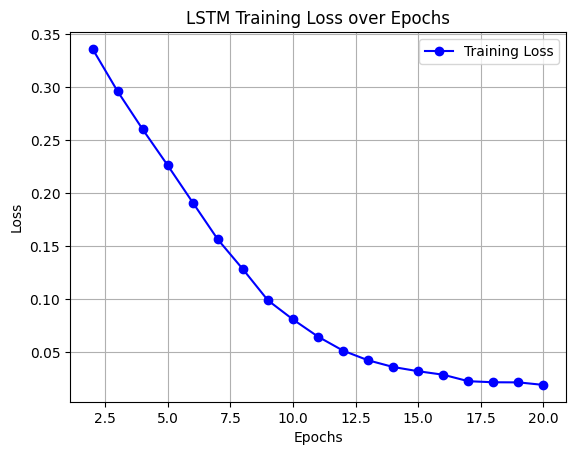

In [41]:
train_losses = [0.3360, 0.2960, 0.2602, 0.2262, 0.1912, 0.1564, 0.1284, 0.0990, 0.0810, 0.0648, 0.0516, 0.0425, 0.0362, 0.0322, 0.0289, 0.0228, 0.0218, 0.0217, 0.0193]
epochs = range(2, 21) 

plt.plot(epochs, train_losses, 'b-o', label='Training Loss')
plt.title('LSTM Training Loss over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

### 📊 Phase 2 Results: LSTM Performance Analysis

After training the LSTM model for 20 epochs, we observed the following performance metrics:

* **Peak Performance**: The model reached its highest accuracy of **85.09%** at **Epoch 3**, with a balanced F1-score for both positive and negative sentiments.
* **Training Dynamics**: 
    * Initial epochs showed rapid learning and improvement in generalization.
    * Beyond Epoch 7, we observed a divergence: while the `train_loss` continued to drop significantly (reaching 0.019), the test accuracy began to fluctuate and slightly decline.
* **Overfitting Observation**: This behavior indicates **Overfitting**, where the model starts memorizing the training data rather than generalizing. In a production environment, we would use the weights from Epoch 3 (**Early Stopping**).

**Key Takeaway**: The LSTM achieved comparable results to the baseline but showed more potential in capturing nuances during its optimal training phase.

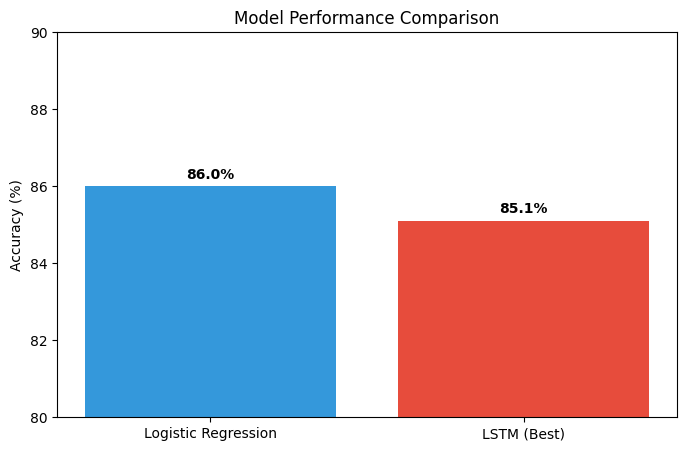

In [40]:

models = ['Logistic Regression', 'LSTM (Best)']
accuracies = [86.0, 85.1] 

plt.figure(figsize=(8, 5))
plt.bar(models, accuracies, color=['#3498db', '#e74c3c'])
plt.ylim(80, 90) 
plt.ylabel('Accuracy (%)')
plt.title('Model Performance Comparison')
for i, v in enumerate(accuracies):
    plt.text(i, v + 0.2, str(v) + '%', ha='center', fontweight='bold')
plt.show()

## 🏁 Final Project Conclusion

This project successfully explored two different approaches to Sentiment Analysis on Persian Digikala reviews:

1. **Logistic Regression (Baseline)**: Proved to be highly efficient and robust, achieving **86% accuracy** with minimal computational cost. It highlights that for many sentiment tasks, well-preprocessed text and TF-IDF can be extremely powerful.
2. **LSTM (Deep Learning)**: Achieved a peak accuracy of **85%**. While it requires more tuning and is susceptible to overfitting, it offers a framework for understanding complex sentence structures that simple bag-of-words models cannot capture.

**Future Improvements**:
- Implementation of **Pre-trained Transformer models** like **ParsBERT** for potentially higher accuracy.
- Using **Early Stopping** to prevent overfitting in deep neural networks.
- Expanding the dataset to include more diverse categories of products.